# EDA 02 — расширенная таблица геологических признаков

**Источник данных:** `data/processed/features_table_geo.csv` (не `features_table.csv`).

Цель — проверить качество и геологическую информативность шести предикторов: elevation, magnetic, gravity, lithology_group, dist_fault_km, dist_contact_km. Известные месторождения — Positive, остальные ячейки — Unlabeled background, а не подтверждённые отрицательные объекты. При 11 positives все сравнения exploratory и не дают статистически надёжных выводов.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "data" / "processed").exists(): ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "processed" / "features_table_geo.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path("../../data/processed/features_table_geo.csv")
df = pd.read_csv(DATA_PATH)
print("Файл:", DATA_PATH.resolve(), "\nРазмер:", df.shape)
display(df.head())

Файл: D:\Uni\Сборники\3 курс\Командная разработка\Удалённый репозиторий\data\processed\features_table_geo.csv 
Размер: (35694, 13)


,x,y,latitude,longitude,is_deposit,deposit_name,fold_id,elevation,magnetic,gravity,lithology_group,dist_fault_km,dist_contact_km
0,459500.0,6485500.0,58.508188,92.304945,0,NaN,3,122.0,-176.118240,62.864227,NaN,7.322580,11.033951
1,459500.0,6486500.0,58.517168,92.304768,0,NaN,3,114.0,-180.356430,63.677711,NaN,7.707406,11.633597
2,459500.0,6487500.0,58.526149,92.304590,0,NaN,1,105.0,-184.596954,64.498230,NaN,7.474147,12.241784
3,459500.0,6488500.0,58.535129,92.304412,0,NaN,1,96.0,-188.797043,65.087418,terrigenous_metaterrigenous,7.240888,12.894173
4,459500.0,6489500.0,58.544110,92.304234,0,NaN,1,92.0,-192.825455,64.723465,NaN,7.072367,13.588897


## 1. Структура, качество и координаты

In [2]:
print(df.info())
display(df.describe(include="all").T)
print("\nПропуски, %:")
display((df.isna().mean()*100).sort_values(ascending=False).to_frame("missing_pct"))
print("Дубликаты строк:", df.duplicated().sum())
print("Дубликаты координат:", df.duplicated(["x","y"]).sum())
required = {"x","y","latitude","longitude","is_deposit","fold_id","elevation","magnetic","gravity","lithology_group","dist_fault_km","dist_contact_km"}
print("Отсутствующие обязательные колонки:", sorted(required-set(df.columns)))
assert required.issubset(df.columns)
assert set(df.is_deposit.dropna().unique()).issubset({0,1})
print("Positive:", int((df.is_deposit==1).sum()), "Unlabeled:", int((df.is_deposit==0).sum()))
print("Fold counts:"); display(df.groupby("fold_id").agg(cells=("is_deposit","size"), positives=("is_deposit","sum")))
print("Диапазон lon/lat:", df.longitude.min(), df.longitude.max(), df.latitude.min(), df.latitude.max())
print("Диапазон x/y (метры, ожидается UTM 46N):", df.x.min(), df.x.max(), df.y.min(), df.y.max())

<class 'pandas.DataFrame'>
RangeIndex: 35694 entries, 0 to 35693
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   x                35694 non-null  float64
 1   y                35694 non-null  float64
 2   latitude         35694 non-null  float64
 3   longitude        35694 non-null  float64
 4   is_deposit       35694 non-null  int64  
 5   deposit_name     11 non-null     str    
 6   fold_id          35694 non-null  int64  
 7   elevation        35694 non-null  float64
 8   magnetic         35694 non-null  float64
 9   gravity          35694 non-null  float64
 10  lithology_group  35288 non-null  str    
 11  dist_fault_km    35694 non-null  float64
 12  dist_contact_km  35694 non-null  float64
dtypes: float64(9), int64(2), str(2)
memory usage: 4.4 MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
x,35694.0,NaN,NaN,NaN,536760.547991,44086.768408,459500.0,498500.0,536500.0,574500.0,616500.0
y,35694.0,NaN,NaN,NaN,6600445.172858,67490.235465,6484500.0,6541500.0,6599500.0,6658500.0,6719500.0
latitude,35694.0,NaN,NaN,NaN,59.538384,0.606075,58.500021,59.012475,59.533113,60.062628,60.599989
longitude,35694.0,NaN,NaN,NaN,93.650128,0.779479,92.300078,92.973615,93.649421,94.324902,94.999971
is_deposit,35694.0,NaN,NaN,NaN,0.000308,0.017552,0.0,0.0,0.0,0.0,1.0
deposit_name,11,11,Sovetskoe Au deposit,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fold_id,35694.0,NaN,NaN,NaN,2.171037,1.238251,0.0,1.0,3.0,3.0,4.0
elevation,35694.0,NaN,NaN,NaN,443.613128,126.211546,82.0,360.0,443.0,526.0,978.0
magnetic,35694.0,NaN,NaN,NaN,-110.049321,122.250981,-282.633392,-180.625214,-154.09433,-83.763844,384.205627
gravity,35694.0,NaN,NaN,NaN,57.815628,12.424456,6.285794,50.790238,59.54298,66.651367,92.698593



Пропуски, %:


,missing_pct
deposit_name,99.969182
lithology_group,1.137446
latitude,0.000000
y,0.000000
x,0.000000
is_deposit,0.000000
longitude,0.000000
elevation,0.000000
fold_id,0.000000
magnetic,0.000000


Дубликаты строк: 0
Дубликаты координат: 0
Отсутствующие обязательные колонки: []
Positive: 11 Unlabeled: 35683
Fold counts:


,cells,positives
fold_id,,
0,4874,1
1,7273,2
2,3359,2
3,17250,5
4,2938,1


Диапазон lon/lat: 92.3000777 94.9999709 58.500021 60.5999888
Диапазон x/y (метры, ожидается UTM 46N): 459500.0 616500.0 6484500.0 6719500.0


### Выводы по качеству данных

Таблица содержит 35 694 ячейки, из которых 11 имеют
статус известных месторождений, а 35 683 относятся
к Unlabeled background.

Дубликаты строк и координат не обнаружены.
Координаты находятся в ожидаемом диапазоне тестовой
площади Енисейского кряжа.

Все числовые предикторы заполнены. Единственный
геологический признак с пропусками — lithology_group:
406 ячеек (1,14%).

Пропуск литологии не следует автоматически трактовать
как отдельный тип пород. Перед обучением нужно проверить
источник пропусков и решить, использовать ли отдельную
категорию Unknown или исключить эти ячейки из расчёта
конкретного признака.

**Ограничение:** 11 известных месторождений — очень
небольшая выборка относительно 35 694 ячеек. Все
дальнейшие сравнения имеют exploratory-характер.

## 2. Распределения признаков: Positive против Unlabeled

Сравнение описательное: класс Unlabeled содержит потенциально минерализованные, но пока не известные участки.

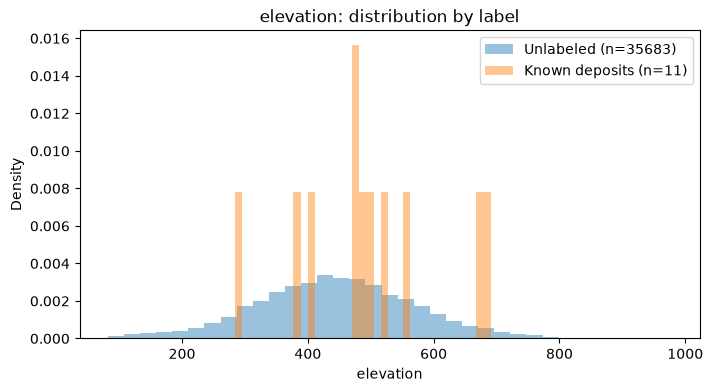

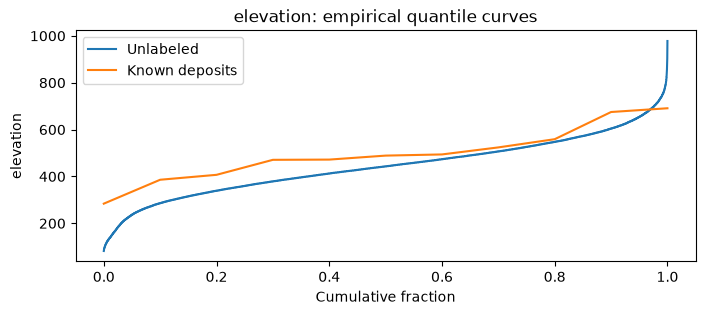

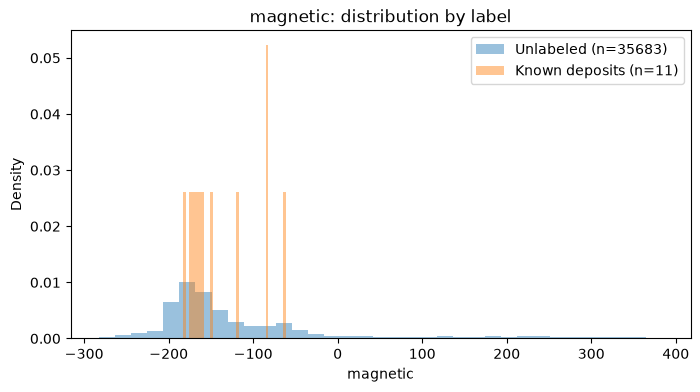

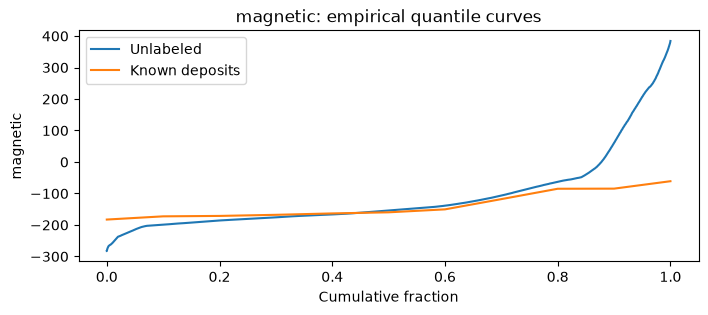

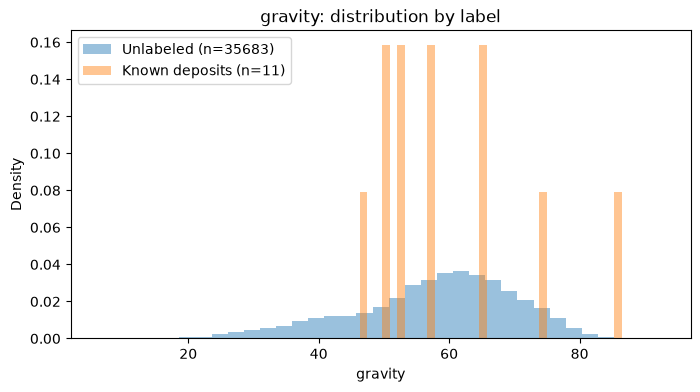

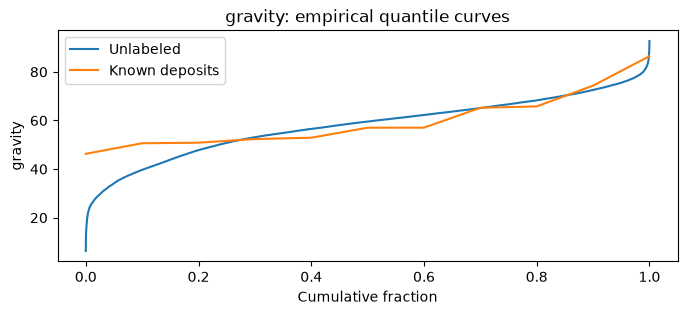

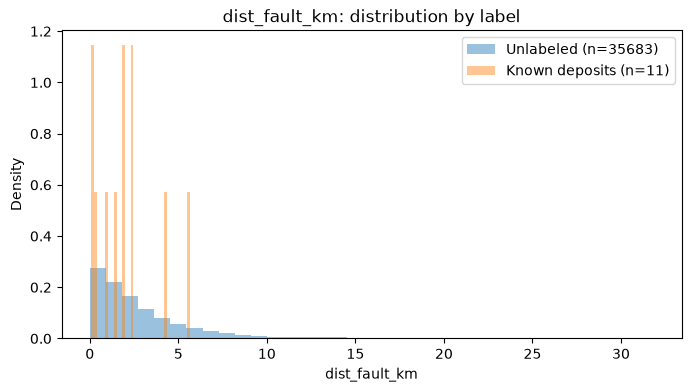

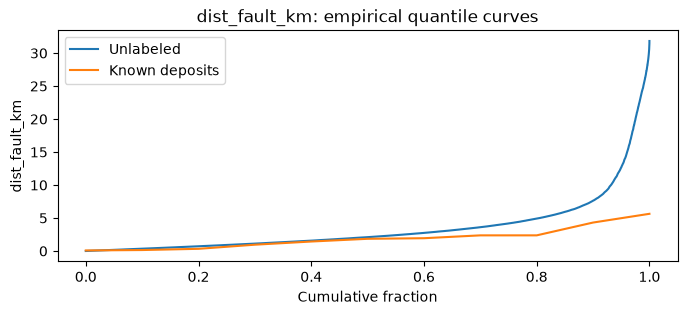

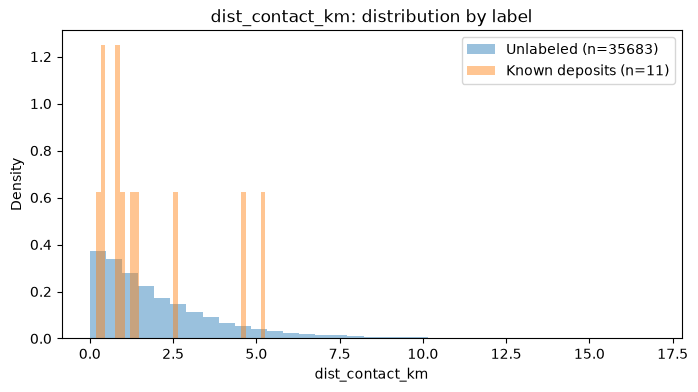

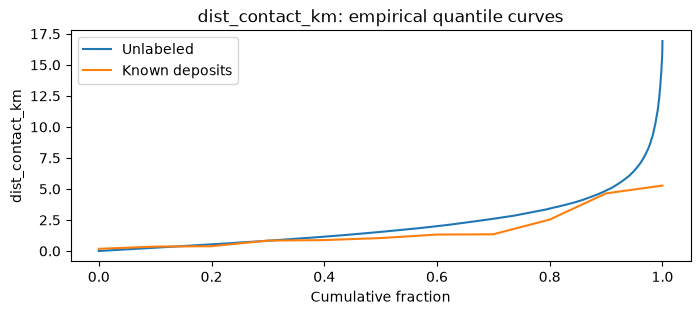

In [3]:
numeric = ["elevation","magnetic","gravity","dist_fault_km","dist_contact_km"]
for col in numeric:
    fig, ax = plt.subplots(figsize=(8,4))
    for label, part in [("Unlabeled",df[df.is_deposit==0]),("Known deposits",df[df.is_deposit==1])]:
        vals=part[col].dropna()
        if len(vals): ax.hist(vals, bins=35, density=True, alpha=.45, label=f"{label} (n={len(vals)})")
    ax.set(title=f"{col}: distribution by label", xlabel=col, ylabel="Density"); ax.legend(); plt.show()
    fig, ax = plt.subplots(figsize=(8,3))
    for label, part in [("Unlabeled",df[df.is_deposit==0]),("Known deposits",df[df.is_deposit==1])]:
        vals=part[col].dropna().sort_values().to_numpy()
        if len(vals): ax.plot(np.linspace(0,1,len(vals)), vals, label=label)
    ax.set(title=f"{col}: empirical quantile curves", xlabel="Cumulative fraction", ylabel=col); ax.legend(); plt.show()

### Выводы по качеству данных

Таблица содержит 35 694 ячейки, из которых 11 имеют
статус известных месторождений, а 35 683 относятся
к Unlabeled background.

Дубликаты строк и координат не обнаружены.
Координаты находятся в ожидаемом диапазоне тестовой
площади Енисейского кряжа.

Все числовые предикторы заполнены. Единственный
геологический признак с пропусками — lithology_group:
406 ячеек (1,14%).

Пропуск литологии не следует автоматически трактовать
как отдельный тип пород. Перед обучением нужно проверить
источник пропусков и решить, использовать ли отдельную
категорию Unknown или исключить эти ячейки из расчёта
конкретного признака.

**Ограничение:** 11 известных месторождений — очень
небольшая выборка относительно 35 694 ячеек. Все
дальнейшие сравнения имеют exploratory-характер.

## 3. Литологические группы

Литология отражает типы пород и геологические комплексы. Пропуск категории нельзя автоматически интерпретировать как отдельную породу.

,cells,known_deposits,positive_rate_vs_all_cells
lithology_group,,,
terrigenous_metaterrigenous,16566,5,0.000302
mixed_terrigenous_carbonate,8755,1,0.000114
high_grade_metamorphic,2554,2,0.000783
mafic_ultramafic,2448,2,0.000817
felsic_intrusive,2323,0,0.000000
carbonate_metacarbonate,2271,0,0.000000
<missing>,406,0,0.000000
other_bedrock,371,1,0.002695


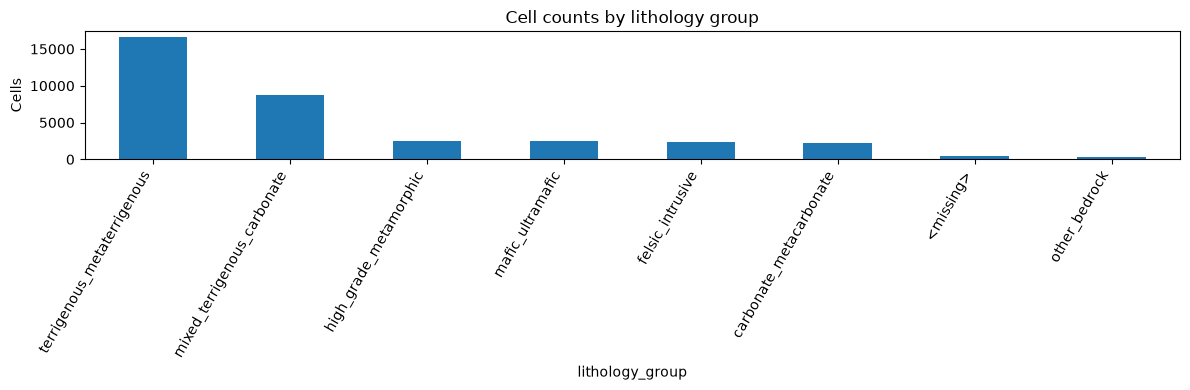

In [4]:
lit = df.assign(lithology_group=df.lithology_group.fillna("<missing>"))
summary = lit.groupby("lithology_group").agg(cells=("is_deposit","size"), known_deposits=("is_deposit","sum"))
summary["positive_rate_vs_all_cells"] = summary.known_deposits / summary.cells
display(summary.sort_values("cells",ascending=False))
ax=summary.sort_values("cells",ascending=False).cells.plot(kind="bar",figsize=(12,4),title="Cell counts by lithology group")
ax.set_ylabel("Cells"); plt.xticks(rotation=60,ha="right"); plt.tight_layout(); plt.show()

### Выводы по качеству данных

Таблица содержит 35 694 ячейки, из которых 11 имеют
статус известных месторождений, а 35 683 относятся
к Unlabeled background.

Дубликаты строк и координат не обнаружены.
Координаты находятся в ожидаемом диапазоне тестовой
площади Енисейского кряжа.

Все числовые предикторы заполнены. Единственный
геологический признак с пропусками — lithology_group:
406 ячеек (1,14%).

Пропуск литологии не следует автоматически трактовать
как отдельный тип пород. Перед обучением нужно проверить
источник пропусков и решить, использовать ли отдельную
категорию Unknown или исключить эти ячейки из расчёта
конкретного признака.

**Ограничение:** 11 известных месторождений — очень
небольшая выборка относительно 35 694 ячеек. Все
дальнейшие сравнения имеют exploratory-характер.

## 4. Корреляции и пространственное распределение

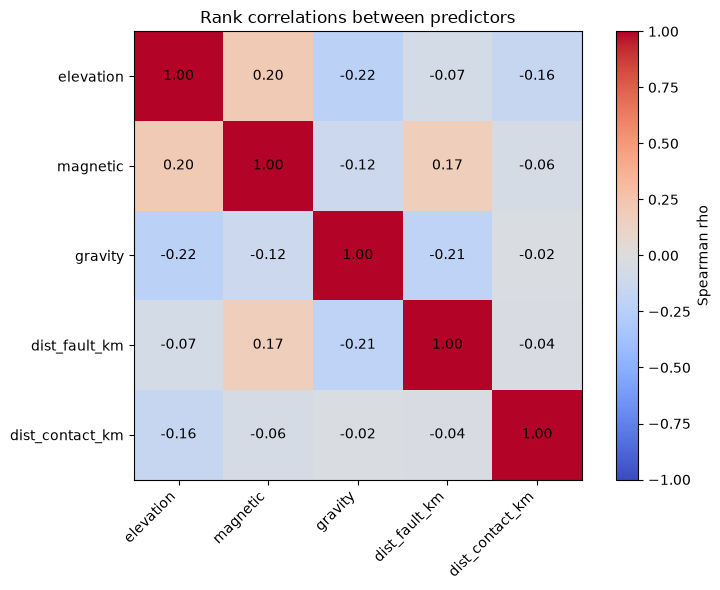

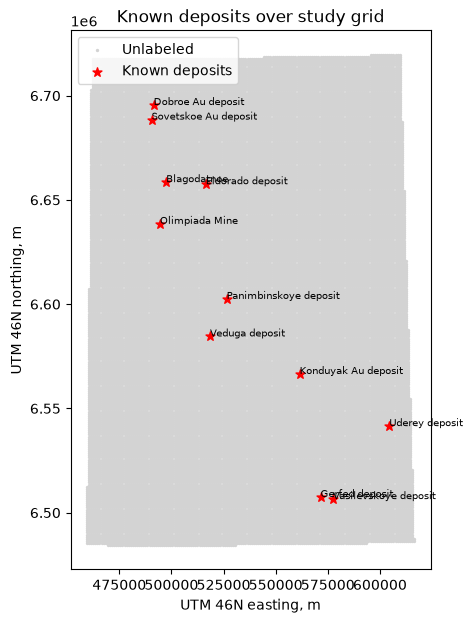

In [5]:
corr = df[numeric].corr(method="spearman")
fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(numeric)),numeric,rotation=45,ha="right"); ax.set_yticks(range(len(numeric)),numeric)
for i in range(len(numeric)):
 for j in range(len(numeric)): ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im,ax=ax,label="Spearman rho"); ax.set_title("Rank correlations between predictors"); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(9,7))
ax.scatter(df.x,df.y,s=2,c="lightgrey",label="Unlabeled")
p=df[df.is_deposit==1]; ax.scatter(p.x,p.y,s=45,c="red",marker="*",label="Known deposits")
for _,r in p.iterrows(): ax.annotate(str(r.get("deposit_name","")),(r.x,r.y),fontsize=7)
ax.set_aspect("equal"); ax.set_xlabel("UTM 46N easting, m"); ax.set_ylabel("UTM 46N northing, m"); ax.legend(); ax.set_title("Known deposits over study grid"); plt.show()

### Выводы по корреляциям и пространственному распределению

Среди числовых предикторов не обнаружено сильных
парных ранговых корреляций. Максимальная по модулю
корреляция составляет около 0.22.

Это снижает риск очевидного дублирования одного и того
же сигнала при суммировании WoE, но не гарантирует
условную независимость признаков.

Известные месторождения распределены по площади
неравномерно. Поэтому при оценке модели необходимо
сохранять пространственное разбиение по fold_id.

Карта показывает расположение известных объектов,
но сама по себе не позволяет судить о полноте
геологической изученности территории.

## 5. Итоговые выводы EDA

1. Таблица features_table_geo.csv содержит шесть
   геологических предикторов и 35 694 ячейки.
2. Пропуски обнаружены только в lithology_group
   (1,14% ячеек).
3. Распределения elevation и magnetic у известных
   месторождений отличаются от Unlabeled-фона,
   но выборка Positive слишком мала для надёжных
   статистических выводов.
4. Dist_fault_km и dist_contact_km представляют
   интерес для проверки структурного контроля
   минерализации.
5. Сильной парной корреляции между числовыми
   предикторами не обнаружено.
6. Литологические категории требуют сглаживания
   и осторожной интерпретации из-за малого числа
   известных объектов.

### Решение для следующего этапа

Использовать все шесть признаков в расширенном WoE
эксперименте. Числовые признаки дискретизировать
на 3, 5 и 7 бинов; литологию оставить категориальной.

Все границы бинов и WoE-веса рассчитывать только
на обучающей части каждого Spatial CV фолда.

Не интерпретировать Unlabeled как отрицательный класс.